In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [4]:
d = pd.read_csv("../results/real_data_results_251219172746.csv")
# compute mean and std fair_metric and value grouped by zvar and method for all groups at once
d.groupby(["method", "zvar"])[["fair_metric", "value"]].agg([np.mean, np.std])

fair_metric                value          
                                    mean       std       mean       std
method           zvar                                                  
ECOCF            education_b    0.059226  0.020774  57.276832  0.470167
                 ethnicity_b    0.121230  0.043306  56.928115  0.849902
                 race_b         0.049603  0.017022  57.181591  0.491172
                 sex_b          0.069643  0.025540  57.443857  0.477722
FLAP             education_b    0.096627  0.029269  57.419517  0.465382
                 ethnicity_b    0.146925  0.048298  57.179895  0.809265
                 race_b         0.074702  0.036236  57.477511  0.467651
                 sex_b          0.088889  0.022930  57.459352  0.538970
full             education_b    0.527480  0.154631  57.312325  0.478737
                 ethnicity_b    0.418056  0.189684  57.125952  0.853870
                 race_b         0.483532  0.217998  57.345731  0.463439
                 sex_b          0.654663  0.175088  57.333596  0.497508
ours_cf1_single  education_b    0.050794  0.028189  57.305649  0.565486
                 ethnicity_b    0.054563  0.037992  57.107573  0.848901
                 race_b         0.031647  0.017154  57.373289  0.439605
                 sex_b          0.036806  0.018362  57.300333  0.629228
ours_cf20_single education_b    0.041369  0.020022  57.224111  0.477461
                 ethnicity_b    0.039286  0.024739  57.027834  0.767314
                 race_b         0.036607  0.026281  57.469712  0.447132
                 sex_b          0.038690  0.017697  57.226285  0.557327
random           education_b    0.000000  0.000000  57.106900  0.375856
                 ethnicity_b    0.000000  0.000000  56.870209  0.718541
                 race_b         0.000000  0.000000  57.105332  0.433135
                 sex_b          0.000000  0.000000  57.116124  0.432632
unaware          education_b    0.151190  0.048164  57.359799  0.556485
                 ethnicity_b    0.119643  0.043198  57.161847  0.764197
                 race_b         0.100496  0.034823  57.387053  0.476838
                 sex_b          0.056448  0.019283  57.473497  0.525918

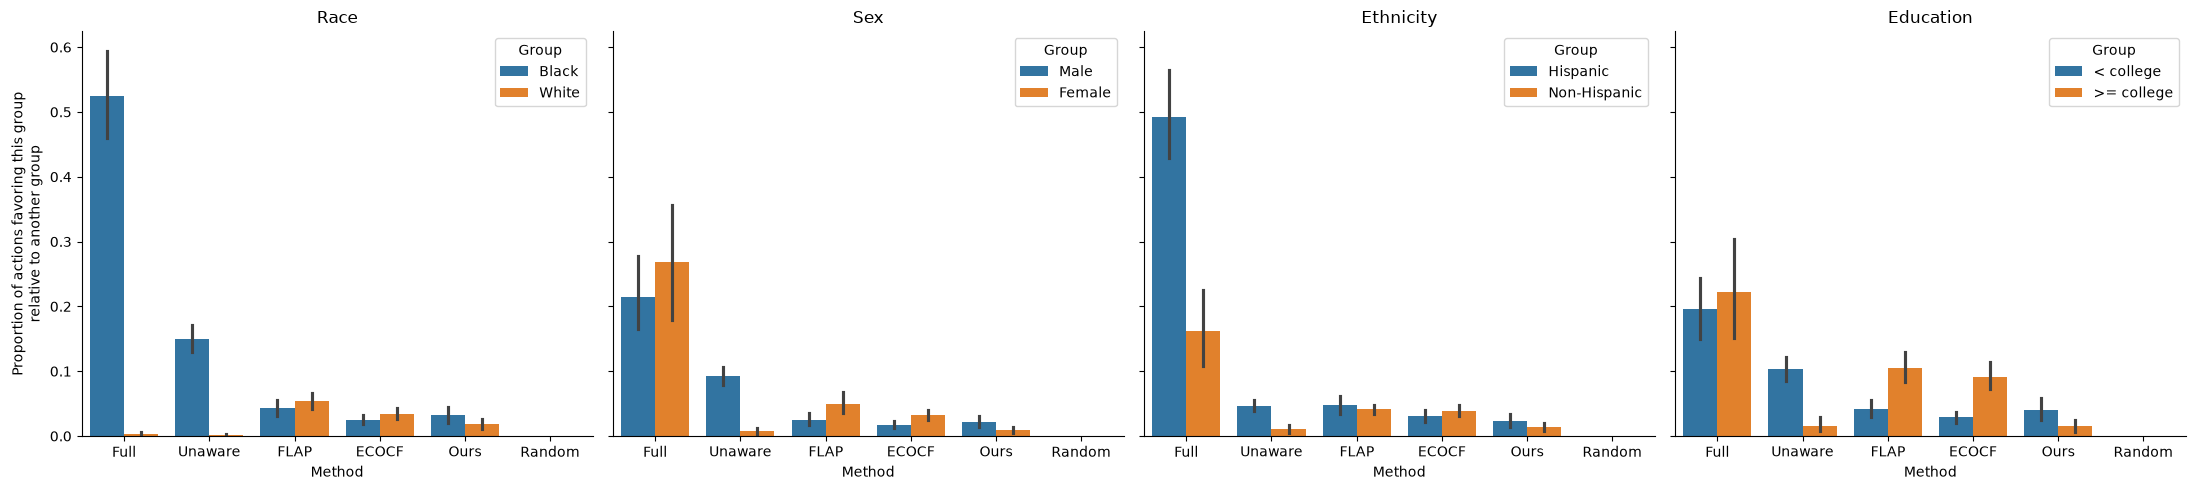

In [7]:
tmp = d[["method", "zvar", "mean_actions_z1lez0", "mean_actions_z1gez0"]]
tmp = pd.melt(
    tmp,
    id_vars=["method", "zvar"],
    value_vars=["mean_actions_z1lez0", "mean_actions_z1gez0"],
    var_name="type",
    value_name="value",
)
tmp = tmp.loc[tmp["method"] != "ours_cf20_single", :]
new_method_labels = {
    "full": "Full",
    "unaware": "Unaware",
    "FLAP": "FLAP",
    "ECOCF": "ECOCF",
    "ours_cf1_single": "Ours",
    "random": "Random",
}
order = ["Full", "Unaware", "FLAP", "ECOCF", "Ours", "Random"]
tmp["method"] = tmp["method"].map(new_method_labels)


g = sns.catplot(
    data=tmp, x="method", y="value", hue="type", kind="bar", col="zvar", order=order
)
# g.set_xticklabels(rotation=45, ha="right")
g._legend.remove()
handles = g.axes.flat[-1].get_legend_handles_labels()[0]
# race, sex, ethnicity, education
labels = [
    ["Black", "White"],
    ["Male", "Female"],
    ["Hispanic", "Non-Hispanic"],
    ["< college", ">= college"],
]
titles = ["Race", "Sex", "Ethnicity", "Education"]
for i, ax in enumerate(g.axes.flat):
    ax.legend(handles, labels[i], title="Group", loc="upper right", frameon=True)
    ax.set_title(titles[i])
    ax.set_xlabel("Method")
    ax.set_ylabel(
        "Proportion of actions favoring this group\nrelative to another group"
    )

plt.tight_layout()
g.savefig(
    "../figures/real_data_actions_difference.png",
    dpi=300,
)